# RF elimination: visual test

Personal experiment (scratch). Goal: **see that the iterative Random Forest elimination works** before running it on the real candidates.

How we check it:
1. **The curve has the expected shape:** the validation error stays flat while we remove useless features, then rises when we remove useful ones.
2. **Control test:** we add a column of **pure random noise**. It has no link with the price, so a working method must remove it in the first rounds.

Small settings (5k sample, few trees) so it runs in about a minute. The curve is noisy: don't draw conclusions about the features here.

## Setup
Paths are relative. `FAST_MODE` uses the 5k sample and a small forest.

In [1]:
import sys
sys.path.append("..")       # notebooks/scratch/ -> notebooks/
sys.path.append("../..")    # -> project root, so `src` can be imported

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession, functions as F

from src.cleaning import clean
from src.feature_selection import split_for_selection, rf_elimination, choose_features

FAST_MODE = False
DATA_PATH = "../../data/sample/listings_sample.csv" if FAST_MODE else "../../data/raw/listings.csv"
RF_SETTINGS = dict(seeds=(42, 43), num_trees=20, max_depth=6) if FAST_MODE else {}

spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/27 16:16:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Load and clean
Same cleaning as the main pipeline (`clean()`, the current 16 features).

In [2]:
raw = spark.read.csv(DATA_PATH, header=True, multiLine=True, escape='"')
df = clean(raw)
print(f"{df.count()} rows after cleaning")

[Stage 1:>                                                          (0 + 1) / 1]

41989 rows after cleaning


## Add the control feature: random noise
`F.rand(seed=1)` gives each row a random number between 0 and 1. It contains **no information about the price**.
If the method works, `random_noise` must be among the first features removed.

In [3]:
df = df.withColumn("random_noise", F.rand(seed=1))

num_cols = ["accommodates", "bedrooms", "beds", "bathrooms", "latitude", "longitude",
            "dist_center_km", "review_scores_rating", "number_of_reviews", "host_is_superhost",
            "minimum_nights", "availability_365", "n_amenities", "random_noise"]
cat_cols = ["room_type", "property_type", "neighbourhood_cleansed"]
print(len(num_cols) + len(cat_cols), "features (16 real + 1 noise)")

17 features (16 real + 1 noise)


## Split and run the elimination
Split by hash of `id`: 60% fit, 20% validation, 20% test (not used here).

In [4]:
fit_df, valid_df = split_for_selection(df)
print(f"fit: {fit_df.count()} rows | validation: {valid_df.count()} rows")

rounds = rf_elimination(fit_df, valid_df, num_cols, cat_cols, **RF_SETTINGS)

fit: 25303 rows | validation: 8293 rows


 17 features | RMSE (log) = 0.3636 | R² = 0.697 | removing: ['host_is_superhost']


 16 features | RMSE (log) = 0.3635 | R² = 0.697 | removing: ['random_noise']


 15 features | RMSE (log) = 0.3634 | R² = 0.698 | removing: ['room_type']


 14 features | RMSE (log) = 0.3640 | R² = 0.696 | removing: ['latitude']


 13 features | RMSE (log) = 0.3648 | R² = 0.695 | removing: ['dist_center_km']


... (7 outputs left out)

  5 features | RMSE (log) = 0.4119 | R² = 0.611 | removing: ['bathrooms']


  4 features | RMSE (log) = 0.4169 | R² = 0.602 | removing: ['neighbourhood_cleansed']


  3 features | RMSE (log) = 0.4639 | R² = 0.507 | removing: ['bedrooms']


  2 features | RMSE (log) = 0.4755 | R² = 0.482 | removing: []


## Check 1: when was the noise removed?

In [5]:
order = [f for removed in rounds["removed_next"] for f in removed]
order += rounds.iloc[-1]["features"]          # the last 2 are never removed
position = order.index("random_noise") + 1
print(f"Elimination order: {order}")
print(f"\nrandom_noise was removed in position {position} of {len(order)}")

Elimination order: ['host_is_superhost', 'random_noise', 'room_type', 'latitude', 'dist_center_km', 'number_of_reviews', 'longitude', 'n_amenities', 'review_scores_rating', 'availability_365', 'beds', 'property_type', 'bathrooms', 'neighbourhood_cleansed', 'bedrooms', 'accommodates', 'minimum_nights']

random_noise was removed in position 2 of 17


## Check 2: the curve
Validation RMSE against the number of features. The green band is the 1% tolerance; the red point is the set chosen by `choose_features`.

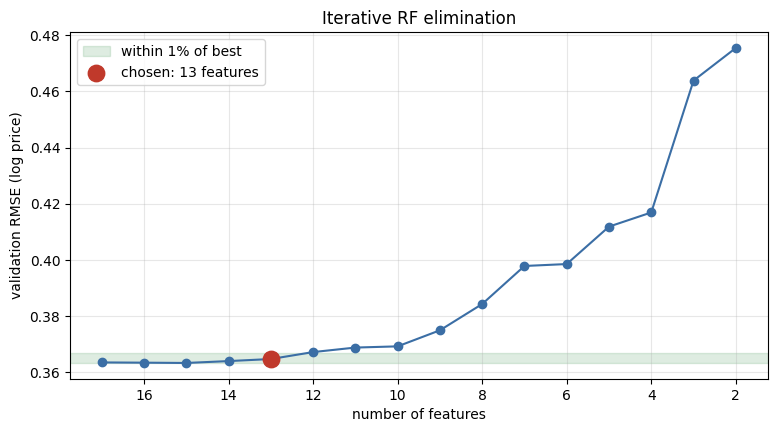

Chosen features: ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'longitude', 'dist_center_km', 'review_scores_rating', 'number_of_reviews', 'minimum_nights', 'availability_365', 'n_amenities', 'property_type', 'neighbourhood_cleansed']


In [6]:
chosen = choose_features(rounds)
best = rounds["rmse_log"].min()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rounds["n_features"], rounds["rmse_log"], marker="o", color="#3b6ea5")
ax.axhspan(best, best * 1.01, color="#5aa469", alpha=0.2, label="within 1% of best")
ax.scatter([len(chosen)], rounds.loc[rounds["n_features"] == len(chosen), "rmse_log"],
           s=140, color="#c0392b", zorder=3, label=f"chosen: {len(chosen)} features")
ax.invert_xaxis()                              # read left to right: many -> few features
ax.set_xlabel("number of features")
ax.set_ylabel("validation RMSE (log price)")
ax.set_title("Iterative RF elimination")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Chosen features:", chosen)

## Check 3: importances in the first round (all features)
The noise should be near the bottom.

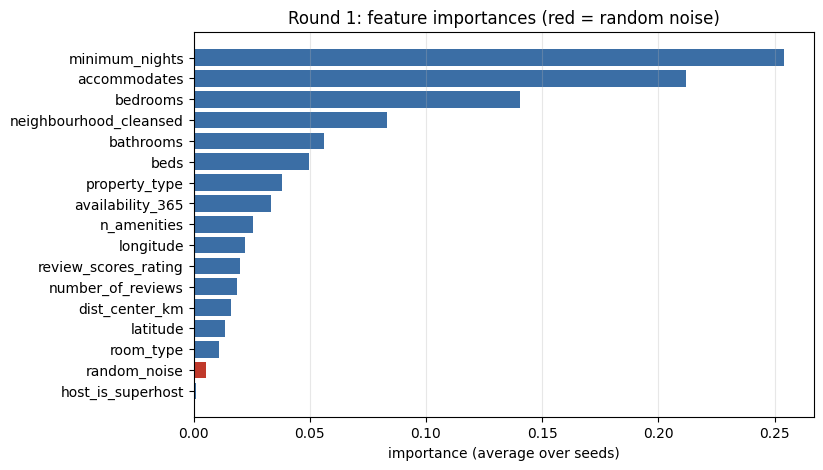

In [7]:
imp = pd.Series(rounds.iloc[0]["importances"]).sort_values()
colors = ["#c0392b" if f == "random_noise" else "#3b6ea5" for f in imp.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=colors)
ax.set_xlabel("importance (average over seeds)")
ax.set_title("Round 1: feature importances (red = random noise)")
ax.grid(axis="x", alpha=0.3)
plt.show()

## Full table of rounds

In [8]:
rounds[["n_features", "rmse_log", "r2", "removed_next"]]

,n_features,rmse_log,r2,removed_next
0,17,0.363567,0.697201,[host_is_superhost]
1,16,0.363481,0.697345,[random_noise]
2,15,0.363375,0.697521,[room_type]
3,14,0.364048,0.696400,[latitude]
4,13,0.364779,0.695179,[dist_center_km]
5,12,0.367250,0.691036,[number_of_reviews]
6,11,0.368858,0.688324,[longitude]
7,10,0.369287,0.687599,[n_amenities]
8,9,0.374999,0.677859,[review_scores_rating]
9,8,0.384351,0.661591,[availability_365]
